# Data Analysis Assignment

**Name: Hejuntian Huang | Student ID: 22301170100**

This notebook completes each question of the assignment in its own section:
1. What steps are involved in data preprocessing?
2. What is an outlier?
3. Reproduce an elegant sin and cos plot
4. Draw a grid of scatter plots with `plt.subplot`
5. Draw a boxplot and explain each part of the box
6*. Use the seaborn penguins dataset: explore its features, draw a scatter plot, boxplot, violin plot and pair plot, and perform a PCA analysis

## 0. Setup

Import all required libraries and configure matplotlib for display.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
plt.rcParams["axes.unicode_minus"] = False

print("Environment ready")

Environment ready


## Question 1 What steps are involved in data preprocessing?

Data preprocessing transforms raw data into high-quality data suitable for analysis and modeling. It mainly includes the following steps:

| Step | Main content |
|---|---|
| **1. Data cleaning** | Handle **missing values** (deletion, mean/median/mode imputation, interpolation); handle **outliers** (detection, removal or correction); remove **duplicates**; smooth noisy data |
| **2. Data integration** | Merge multiple data sources into one dataset; entity identification and matching; remove redundant attributes; resolve data conflicts |
| **3. Data transformation** | **Standardization** (Z-score, zero mean and unit variance), **normalization** (Min-Max scaling to [0,1]); discretization (binning); categorical encoding (One-hot, Label Encoding); log/square-root transforms |
| **4. Data reduction** | Dimensionality reduction (e.g., PCA); numerosity reduction (sampling, cluster representatives); data compression |
| **5. Data splitting** (before modeling) | Train/test split; handling class imbalance (over-sampling, under-sampling) |

Core purpose: **improve data quality → improve the reliability of analysis and model results**.

## Question 2 What is an outlier?

An **outlier** is an observation that deviates markedly from the overall distribution or from the rest of the sample.

**Common causes:**
- Measurement errors or instrument failure
- Data entry errors
- Sampling errors
- Genuine rare events (in which case the outlier itself may be of great research interest)

**Common detection methods:**

| Method | Decision rule |
|---|---|
| 3-sigma rule | For approximately normal data, a point more than 3 standard deviations from the mean (\|x−μ\| > 3σ) |
| Boxplot / IQR rule | Below **Q1 − 1.5×IQR** or above **Q3 + 1.5×IQR** (IQR = Q3 − Q1), i.e., points beyond the whiskers |
| Z-score / modified Z | A large absolute value after standardization |
| Model-based | Isolation Forest, DBSCAN, LOF, etc. |

**How to handle:** delete, treat as missing and impute, winsorize (cap at limits), bin, or keep and analyze separately (when the outlier represents a real phenomenon).

## Question 3 Reproduce an elegant sin and cos plot

Key points: smooth curves via `np.linspace`; ticks in multiples of π; remove the top/right spines and move the left/bottom spines to the origin; add a legend.

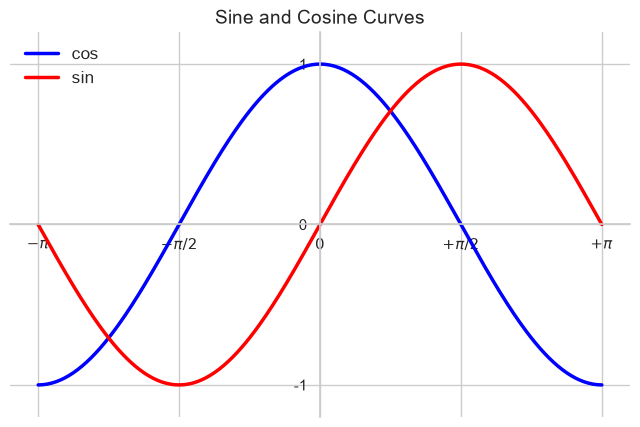

In [2]:
X = np.linspace(-np.pi, np.pi, 256, endpoint=True)
C, S = np.cos(X), np.sin(X)

plt.figure(figsize=(8, 5), dpi=100)
plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-", label="cos")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-", label="sin")

# Move spines to the origin and hide top/right spines
ax = plt.gca()
ax.spines["right"].set_color("none")
ax.spines["top"].set_color("none")
ax.spines["left"].set_position(("data", 0))
ax.spines["bottom"].set_position(("data", 0))

# Ticks in multiples of pi
plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
           [r"$-\pi$", r"$-\pi/2$", r"$0$", r"$+\pi/2$", r"$+\pi$"])
plt.yticks([-1, 0, 1])

plt.xlim(-np.pi * 1.1, np.pi * 1.1)
plt.ylim(-1.2, 1.2)
plt.legend(loc="upper left", frameon=False, fontsize=12)
plt.title("Sine and Cosine Curves", fontsize=14)
plt.show()

## Question 4 Draw a grid of scatter plots with `plt.subplot`

`plt.subplot(rows, cols, index)` places multiple subplots on one canvas. Here we use 4 combinations of the penguins numeric features, colored by species.

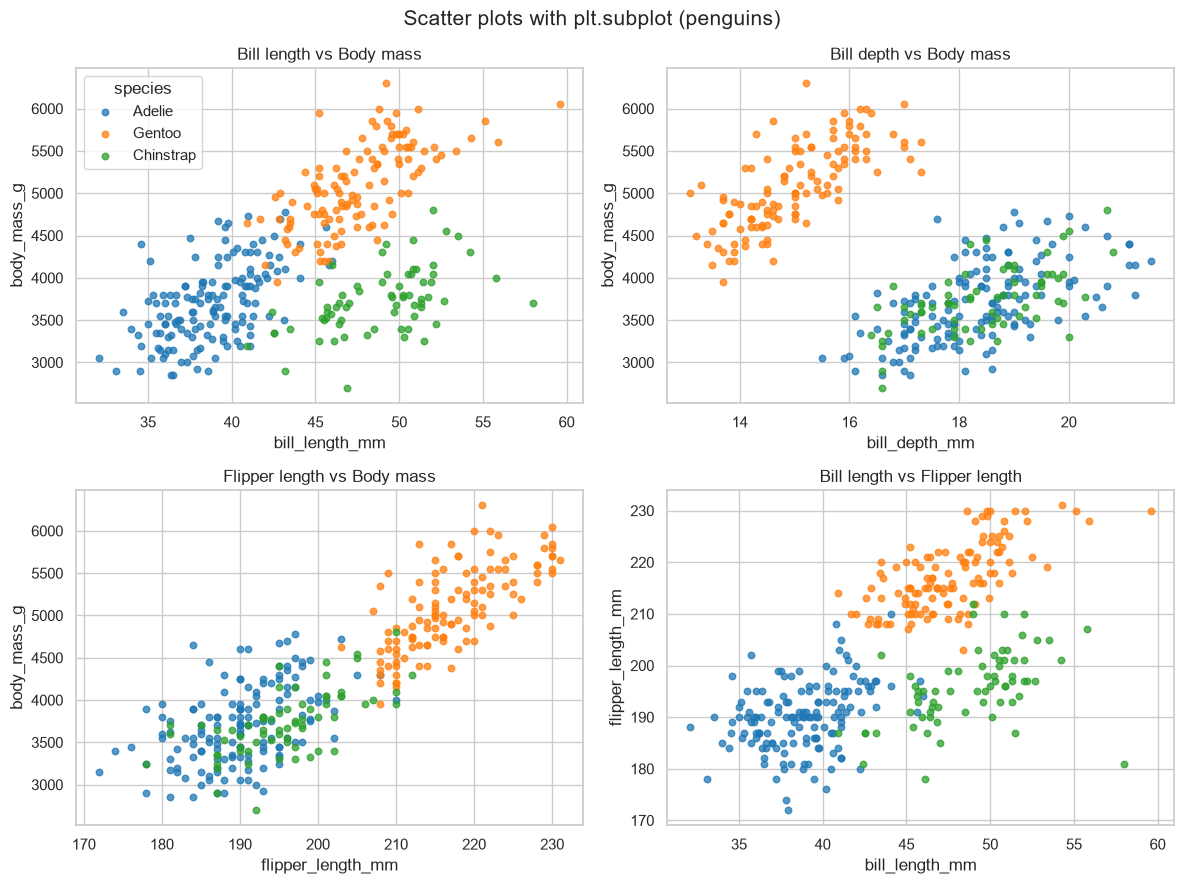

In [3]:
# Load the penguins dataset first (drop missing rows)
penguins = sns.load_dataset("penguins").dropna()

combos = [
    ("bill_length_mm",   "body_mass_g",      "Bill length vs Body mass"),
    ("bill_depth_mm",    "body_mass_g",      "Bill depth vs Body mass"),
    ("flipper_length_mm","body_mass_g",      "Flipper length vs Body mass"),
    ("bill_length_mm",   "flipper_length_mm","Bill length vs Flipper length"),
]
colors = {"Adelie": "#1f77b4", "Gentoo": "#ff7f0e", "Chinstrap": "#2ca02c"}

plt.figure(figsize=(12, 9))
for i, (x, y, title) in enumerate(combos, start=1):
    plt.subplot(2, 2, i)                     # i-th of a 2x2 grid
    for sp, c in colors.items():
        sub = penguins[penguins["species"] == sp]
        plt.scatter(sub[x], sub[y], s=22, alpha=0.75, color=c, label=sp)
    plt.xlabel(x); plt.ylabel(y); plt.title(title)
    if i == 1:
        plt.legend(title="species")
plt.suptitle("Scatter plots with plt.subplot (penguins)", fontsize=15)
plt.tight_layout()
plt.show()

## Question 5 Draw a boxplot and explain each part of the box

C:\Users\Zaraughty\AppData\Local\Temp\ipykernel_42960\1768520335.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = plt.boxplot(data, vert=True, patch_artist=True, widths=0.4,


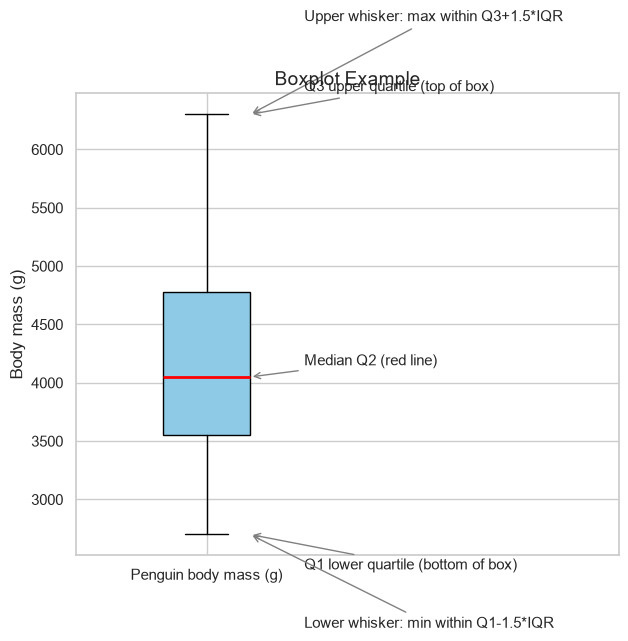

In [4]:
data = penguins["body_mass_g"]

plt.figure(figsize=(7, 6))
bp = plt.boxplot(data, vert=True, patch_artist=True, widths=0.4,
                 boxprops=dict(facecolor="#8ecae6"),
                 medianprops=dict(color="red", linewidth=2),
                 flierprops=dict(marker="o", markerfacecolor="orange"))
plt.xticks([1], ["Penguin body mass (g)"])
plt.ylabel("Body mass (g)")
plt.title("Boxplot Example", fontsize=14)

# Annotate the parts of the box
q1, med, q3 = bp["whiskers"][0].get_ydata()[1], bp["medians"][0].get_ydata()[1], bp["whiskers"][1].get_ydata()[1]
ann = dict(fontsize=11, arrowprops=dict(arrowstyle="->", color="gray"))
plt.annotate("Upper whisker: max within Q3+1.5*IQR", xy=(1.2, q3), xytext=(1.45, q3+800), **ann)
plt.annotate("Q3 upper quartile (top of box)", xy=(1.2, q3), xytext=(1.45, q3+200), **ann)
plt.annotate("Median Q2 (red line)", xy=(1.2, med), xytext=(1.45, med+100), **ann)
plt.annotate("Q1 lower quartile (bottom of box)", xy=(1.2, q1), xytext=(1.45, q1-300), **ann)
plt.annotate("Lower whisker: min within Q1-1.5*IQR", xy=(1.2, q1), xytext=(1.45, q1-800), **ann)
plt.xlim(0.4, 2.9)
plt.show()

**Explanation of each part of the boxplot:**

- **The box**: spans from **Q1 (lower quartile, 25th percentile)** to **Q3 (upper quartile, 75th percentile)** and contains the middle 50% of the data; the box length equals the **IQR (interquartile range)**;
- **Median line (Q2)**: the thick line inside the box (red here), the median of the data, showing its central location;
- **Whiskers**: the two horizontal caps extending to the smallest/largest observations within **Q1 − 1.5×IQR** and **Q3 + 1.5×IQR**;
- **Outliers**: isolated points beyond the whiskers, i.e., anomalous values;
- The position of the median inside the box and the whisker lengths also reveal the **skewness** and **dispersion** of the data.

## Question 6* seaborn penguins dataset: feature exploration, scatter / box / violin / pair plots, and PCA

The penguins dataset contains 344 penguin observations: 3 species (Adelie, Chinstrap, Gentoo), island, bill length, bill depth, flipper length, body mass and sex.

### 6.1 Data exploration

In [5]:
df = sns.load_dataset("penguins")

print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("Column dtypes and missing values:")
df.info()
print("\nDescriptive statistics of numeric features:")
display(df.describe().round(2))
print("Species distribution:")
print(df["species"].value_counts())
print("\nMissing values per column:")
print(df.isna().sum())

# Drop missing rows for a clean dataset
df_clean = df.dropna().reset_index(drop=True)
print("\nShape after dropping missing rows:", df_clean.shape)

Shape: (344, 7)

First 5 rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


Column dtypes and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB

Descriptive statistics of numeric features:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


Species distribution:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Shape after dropping missing rows: (333, 7)


### 6.2 Scatter plot

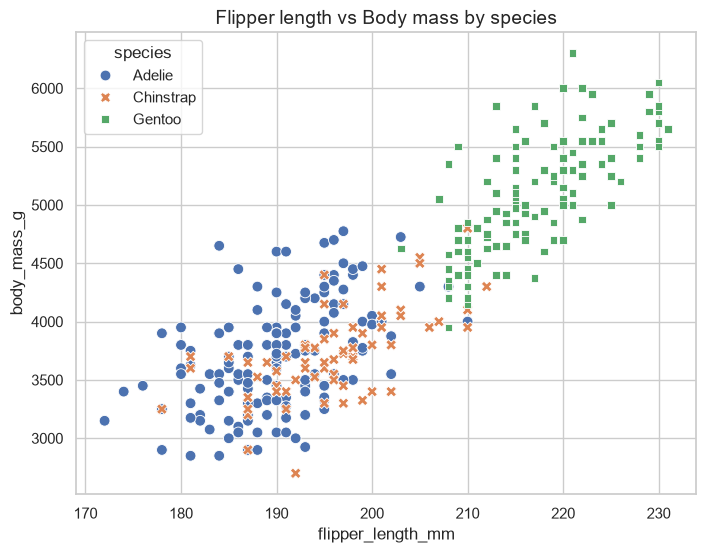

In [6]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_clean, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="species", s=60)
plt.title("Flipper length vs Body mass by species", fontsize=14)
plt.show()

### 6.3 Boxplot

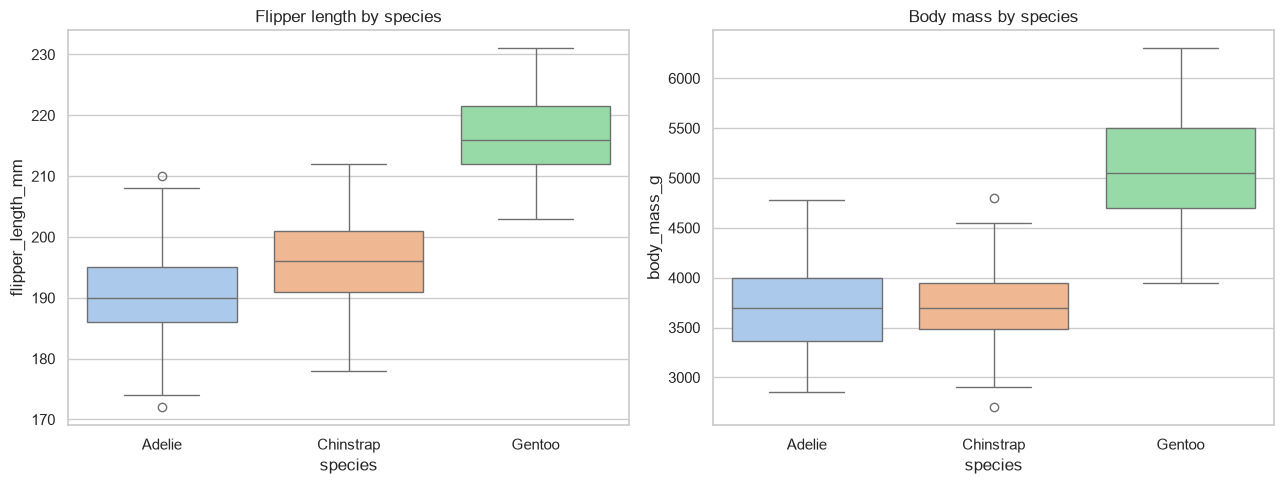

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df_clean, x="species", y="flipper_length_mm", ax=axes[0],
            hue="species", palette="pastel")
axes[0].set_title("Flipper length by species")
sns.boxplot(data=df_clean, x="species", y="body_mass_g", ax=axes[1],
            hue="species", palette="pastel")
axes[1].set_title("Body mass by species")
plt.tight_layout()
plt.show()

### 6.4 Violin plot

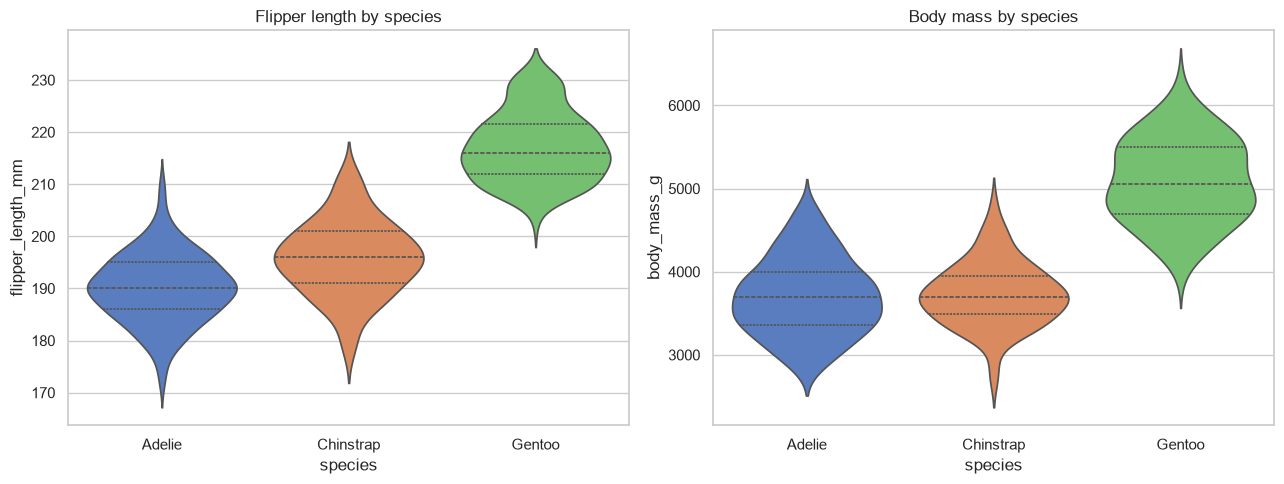

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.violinplot(data=df_clean, x="species", y="flipper_length_mm", ax=axes[0],
               hue="species", palette="muted", inner="quartile")
axes[0].set_title("Flipper length by species")
sns.violinplot(data=df_clean, x="species", y="body_mass_g", ax=axes[1],
               hue="species", palette="muted", inner="quartile")
axes[1].set_title("Body mass by species")
plt.tight_layout()
plt.show()

### 6.5 Pair plot

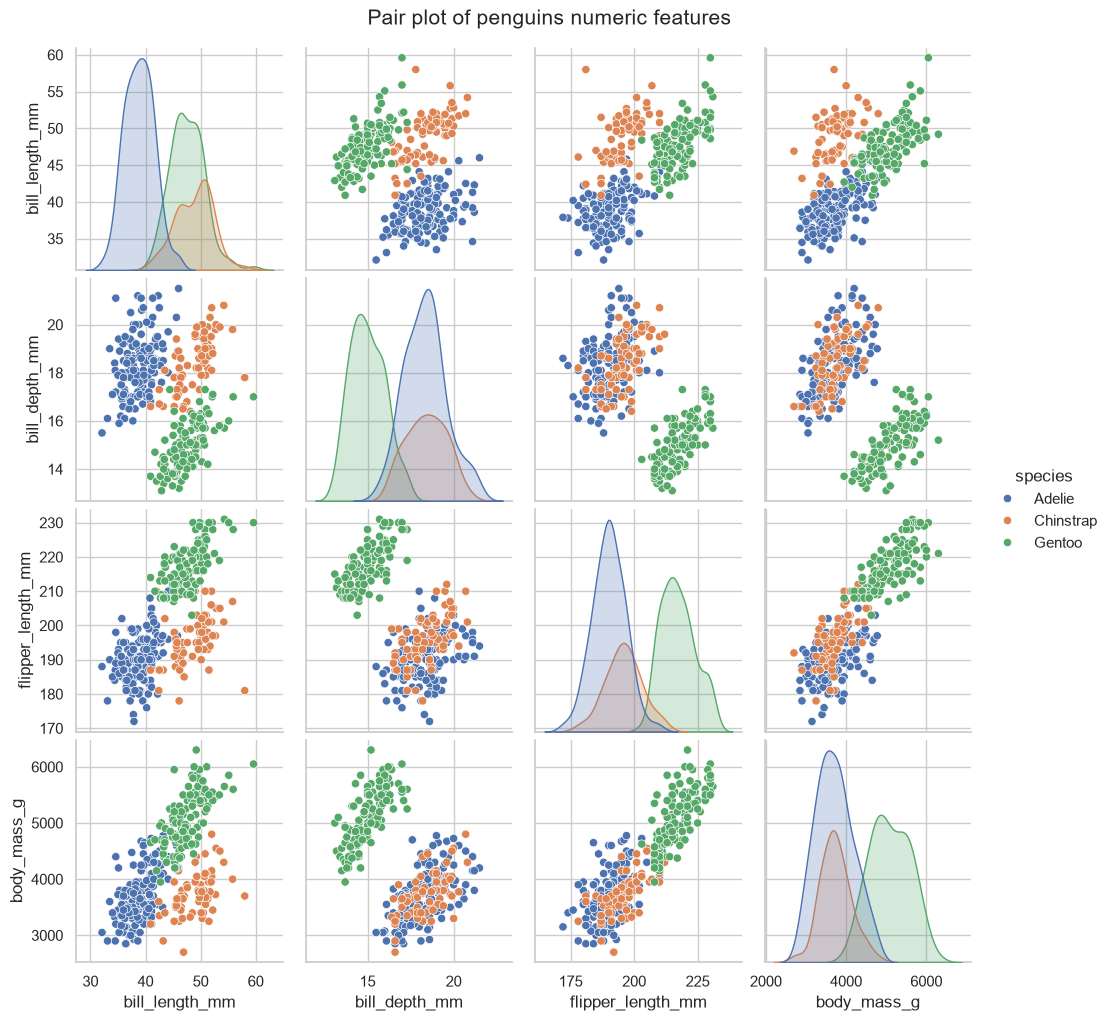

In [9]:
sns.pairplot(df_clean, hue="species", diag_kind="kde",
             vars=["bill_length_mm", "bill_depth_mm",
                   "flipper_length_mm", "body_mass_g"])
plt.suptitle("Pair plot of penguins numeric features", y=1.02, fontsize=15)
plt.show()

### 6.6 PCA (Principal Component Analysis)

Standardize the 4 numeric features (Z-score), then reduce them to 2 dimensions with PCA, and inspect the explained variance ratios and how the species are distributed in the principal-component plane.

Explained variance ratio: [0.6863 0.1945]
Cumulative explained variance: 88.09%

Loadings (each PC is a linear combination of the 4 original features):


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
PC1,0.454,-0.399,0.577,0.550
PC2,0.600,0.796,0.006,0.076


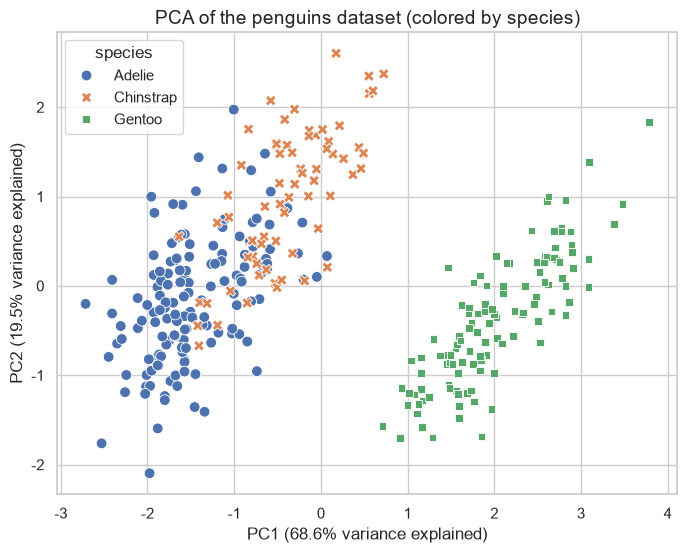

In [10]:
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = df_clean[features].values
X_std = StandardScaler().fit_transform(X)      # standardize

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)

print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Cumulative explained variance: %.2f%%" % (pca.explained_variance_ratio_.sum() * 100))
print("\nLoadings (each PC is a linear combination of the 4 original features):")
display(pd.DataFrame(pca.components_.round(3),
                     columns=features, index=["PC1", "PC2"]))

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["species"] = df_clean["species"].values

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="species", style="species", s=60)
evr = pca.explained_variance_ratio_ * 100
plt.xlabel(f"PC1 ({evr[0]:.1f}% variance explained)")
plt.ylabel(f"PC2 ({evr[1]:.1f}% variance explained)")
plt.title("PCA of the penguins dataset (colored by species)", fontsize=14)
plt.show()

**Interpretation of the PCA results:**
- PC1 is driven mainly by bill length, flipper length and body mass (positive) together with bill depth (negative), representing the penguins' overall "body size";
- The first two components cumulatively explain **88.1%** of the total variance (PC1: 68.6%, PC2: 19.4%), so the information loss from the dimensionality reduction is small;
- In the PC1–PC2 plane, Gentoo is clearly separated, while Adelie and Chinstrap partially overlap but remain distinguishable — meaning 2 principal components already capture most of the morphological differences among the 3 species.